# 05 – Model Comparison and Final Model

This notebook settles the **final model**: the two-stage model of notebook 04 with **no class weight and a per-step offset**, averaged over 6 seeds (public leaderboard **0.96169**). It also audits the validation scheme against the leaderboard, lists every submission, and picks the **two files** for the private leaderboard.

## Goal
Notebook 04 ended with the two-stage model (neighbours' predicted risk), public leaderboard 0.95846. This notebook:
1. tests the **last change**: dropping the class weight and adding a **per-step offset**, in all four combinations;
2. checks how well my way of choosing models (the mean AUC on the 4 late folds, `02_validation_setup.ipynb`) matched the **public leaderboard**;
3. lists **every submission** I made, with its leaderboard score;
4. builds the **final submission** and picks the **two files** for the private leaderboard.

The public leaderboard scores 30% of the test rows; the final ranking uses the other 70%, with the better of my two selected files.

## 0. Setup
All models come from `src/models.py` and all validation from `src/validation.py`, the same code as notebook 04.

**Helpers used for the first time here**
- `step_offset(rows)`: the per-step starting score of each training row (section 2).
- `two_stage_model(..., balanced, use_offset)`: the two-stage model of notebook 04; `balanced` switches the class weight and `use_offset` the per-step offset, in both stages.
- `FOLDS`: the three early folds, used in section 4 to audit the late folds.

In [1]:
import sys
sys.path.append("..")  # add the repo root so `src` can be imported from inside notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load_train, load_test, load_edges, labeled, save_submission, FEATURE_COLS, LABEL_COL, TIME_COL, SUBMISSIONS_DIR
from src.features import build_graph, fit_local_pca, add_graph_features, GRAPH_COLS
from src.models import fit_lightgbm, step_offset, two_stage_model, average_over_seeds
from src.validation import FOLDS, LATE_FOLDS, evaluate_graph_model, log_experiment

pd.set_option("display.width", 150)  # print wide tables on one line

## 1. Load the data and build the graph features
Exactly as in notebook 04: the graph, the PCA of the 93 local features, and the 27 present-neighbour graph columns for the labeled training rows and the test rows.

In [2]:
train, test, edges = load_train(), load_test(), load_edges()
lab = labeled(train).reset_index(drop=True)  # labeled training rows (time steps 1-35)
graph = build_graph(edges, train, test)

pca = fit_local_pca(train)                                 # no labels used
lab_g, test_g = add_graph_features(graph, lab, test, pca)  # + the 27 graph columns, one rule for both
print(f"Labeled rows: {len(lab_g):,} | test rows: {len(test_g):,} | columns: {len(FEATURE_COLS)} raw + {len(GRAPH_COLS)} graph")

Labeled rows: 31,235 | test rows: 15,329 | columns: 165 raw + 27 graph


## 2. Why change the class weight and add a per-step offset?
**The problem.** The share of illicit transactions changes a lot from one training step to the next (0.4% to 36%, `01_eda.ipynb`).
Many features drift over time, so a tree model can tell the steps apart and then score a transaction partly by **which step it resembles** rather than by what it looks like.
The test steps 36–49 have their own, unknown illicit shares, so that part of the score does not carry over.

**Design choices**
1. **Per-step offset.** LightGBM can start each training row from a fixed score (`init_score`) instead of one shared starting value. `step_offset` gives each row the log-odds of its own step's illicit rate minus the log-odds of the overall rate: 0 for a step at the average rate, negative for a less illicit step, positive for a more illicit one. Each step's base rate is then already accounted for, so the trees learn what separates illicit from licit **within** a step. Predictions use the trees only (LightGBM does not add `init_score` when predicting), so no training step's base rate enters the test scores.
2. **No class weight.** Notebooks 03 and 04 used `class_weight="balanced"`, which counts every illicit row several times as much as a licit row. Without it, every row counts the same. Notebook 03 found that the weight helped mainly with the step-24 change and barely changed LightGBM on the late folds.

**Worked example.** Step 13 has 291 illicit rows out of 809, a smoothed rate of (291 + 0.5) / 810 = 0.360, against an overall rate of (3,644 + 0.5) / 31,236 = 0.117. Its offset is logit(0.360) - logit(0.117) = -0.576 - (-2.024) = **+1.448**: every step-13 row starts 1.448 log-odds above an average row before the first tree is built.

The offsets for the labeled training rows:

In [3]:
offsets = lab[[TIME_COL, LABEL_COL]].assign(offset=step_offset(lab))
per_step = offsets.groupby(TIME_COL).agg(rows=(LABEL_COL, "size"), illicit_rate=(LABEL_COL, "mean"), offset=("offset", "first"))

print(f"Overall illicit rate: {lab[LABEL_COL].mean():.3f}")
print(f"class_weight='balanced' counts each illicit row {(lab[LABEL_COL] == 0).sum() / lab[LABEL_COL].sum():.1f} times as much as a licit row")
print("The three time steps with the lowest and the three with the highest illicit rate:")
per_step.sort_values("illicit_rate").iloc[[0, 1, 2, -3, -2, -1]].round(3)

Overall illicit rate: 0.117
class_weight='balanced' counts each illicit row 7.6 times as much as a licit row
The three time steps with the lowest and the three with the highest illicit rate:


,rows,illicit_rate,offset
time_step,,,
5,1882,0.004,-3.372
1,2147,0.008,-2.778
3,1279,0.009,-2.679
28,284,0.299,1.177
9,778,0.319,1.266
13,809,0.360,1.448


**Takeaway:** 11.7% of labeled rows are illicit, so the class weight counts each illicit row 7.6 times as much as a licit one. The offsets range from −3.372 (step 5, 0.4% illicit) to +1.448 (step 13, 36.0% illicit) on the log-odds scale. 
That is the part of each training row's score the trees no longer need to learn, and that the test predictions do not contain.

## 3. Four combinations on the late folds
I compare the two-stage model of notebook 04 in all four combinations of the two settings, plus the baseline and the graph-feature model from notebook 04 as reference points.

**Helper:** `two_stage(balanced, use_offset)` returns the two-stage model function with those settings, in the `model(train_rows, pred_rows, seed)` form that `evaluate_graph_model` expects. `evaluate_graph_model` rebuilds every feature inside each fold, as in notebook 04.

Each two-stage model trains 7 LightGBM models per fold (112 for the four of them), so this cell takes several minutes.

In [4]:
def baseline(train_rows, pred_rows, seed):
    """LightGBM (balanced) on the 165 raw features: the best model of notebook 03."""
    return fit_lightgbm(train_rows, FEATURE_COLS, seed, balanced=True).predict_proba(pred_rows[FEATURE_COLS])[:, 1]


def graph_model(train_rows, pred_rows, seed):
    """The same LightGBM with the 27 present-neighbour graph columns (notebook 04)."""
    cols = FEATURE_COLS + GRAPH_COLS
    return fit_lightgbm(train_rows, cols, seed, balanced=True).predict_proba(pred_rows[cols])[:, 1]


def two_stage(balanced, use_offset):
    """The two-stage model of notebook 04 with the given class weight and offset settings."""
    def model(train_rows, pred_rows, seed):
        return two_stage_model(graph, train_rows, pred_rows, seed, balanced=balanced, use_offset=use_offset)
    return model


# name -> (model function, public leaderboard AUC of its submission, or None if never submitted)
MODELS = {
    "baseline": (baseline, 0.94637),
    "+ graph features": (graph_model, 0.95121),
    "two-stage, class weight, no offset": (two_stage(True, False), 0.95846),  # notebook 04's final model
    "two-stage, class weight + offset": (two_stage(True, True), 0.95933),
    "two-stage, no weight, no offset": (two_stage(False, False), None),
    "two-stage, no weight + offset": (two_stage(False, True), 0.96169),       # the final model
}

late_results = {}
for name, (model, _) in MODELS.items():
    late_results[name] = evaluate_graph_model(model, train, graph, folds=LATE_FOLDS)
    log_experiment(name, late_results[name], notes="05_model_comparison, seed 42")

late_table = pd.DataFrame({name: r.set_index("valid_steps")["auc"] for name, r in late_results.items()}).T
late_table["mean AUC"] = late_table.mean(axis=1)
late_table["public leaderboard"] = pd.Series({name: lb for name, (_, lb) in MODELS.items()})
late_table.round(5)

valid_steps,25-35,27-35,29-35,31-35,mean AUC,public leaderboard
baseline,0.99718,0.99785,0.99742,0.99857,0.99776,0.94637
+ graph features,0.99773,0.99831,0.99796,0.99879,0.99820,0.95121
"two-stage, class weight, no offset",0.99825,0.99886,0.99857,0.99904,0.99868,0.95846
"two-stage, class weight + offset",0.99785,0.99868,0.99851,0.99884,0.99847,0.95933
"two-stage, no weight, no offset",0.99825,0.99883,0.99868,0.99888,0.99866,NaN
"two-stage, no weight + offset",0.99832,0.99885,0.99848,0.99897,0.99865,0.96169


The same results as two 2x2 tables: the late-fold mean AUC from above, and the public leaderboard scores of the submitted files.

In [5]:
two_stage_names = [name for name in MODELS if name.startswith("two-stage")]
grid = pd.DataFrame({
    "class weight": ["balanced", "balanced", "none", "none"],
    "offset": ["none", "per step", "none", "per step"],
    "mean AUC": late_table.loc[two_stage_names, "mean AUC"].to_numpy(),
})
grid.pivot(index="class weight", columns="offset", values="mean AUC").round(5)

offset,none,per step
class weight,,
balanced,0.99868,0.99847
none,0.99866,0.99865


Public leaderboard (typed in from Kaggle):

| class weight \ offset | none | per step |
|---|---|---|
| balanced | 0.95846 (3 seeds) | 0.95933 |
| none | not submitted (see below) | **0.96169** |

The offset files average 6 seeds, the 0.95846 file 3.
The no-weight, no-offset model was not submitted. The nearest submission, `probe_offconst.csv` (no class weight, and **one** constant offset for every step instead of one per step, 6 seeds), scored 0.95888.

**Takeaway:** on the late folds three combinations are level (0.99868, 0.99866 and 0.99865), and class weight + offset is a little lower (0.99847). The leaderboard tells a different story. Each change on its own gained little over 0.95846 (the offset +0.00087, the constant offset without weight +0.00042), while both together gained **+0.00323**.

So the late folds could not choose the last step; the public leaderboard did. Two cautions: the public leaderboard scores only 30% of the test rows, and the offset files average 6 seeds against 3, so part of each gain may come from the extra seeds.

## 4. Did the late folds agree with the leaderboard?
`02_validation_setup.ipynb` chose the late folds to compare models and deferred the check of that choice to this notebook.
For each submitted model above, I plot its late-fold mean AUC against its public leaderboard score, and compare with the early folds (`FOLDS`: validate on steps 21–25, 26–30, 31–35).

The comparison uses the **Spearman rank correlation**: +1 means the folds order the submitted models exactly as the leaderboard does, -1 means the reverse order.
This cell evaluates the 5 submitted models on the 3 early folds, which takes several more minutes.

In [6]:
early_results = {}
for name, (model, lb) in MODELS.items():
    if lb is not None:  # submitted models only
        early_results[name] = evaluate_graph_model(model, train, graph, folds=FOLDS)
        log_experiment(name, early_results[name], notes="05_model_comparison, seed 42")

submitted = pd.DataFrame({
    "late mean": late_table["mean AUC"],
    "early mean": pd.Series({name: r["auc"].mean() for name, r in early_results.items()}),
    "early 21-25": pd.Series({name: r["auc"].iloc[0] for name, r in early_results.items()}),
    "public leaderboard": late_table["public leaderboard"],
}).reindex(late_table.index).dropna()  # same order as the table in section 3
# Rank correlation (Spearman): +1 = the folds order the submitted models exactly like the leaderboard
print("Rank correlation with the public leaderboard (5 submitted models):")
for col in ["late mean", "early mean", "early 21-25"]:
    print(f"  {col:12s} {submitted[col].corr(submitted['public leaderboard'], method='spearman'):+.2f}")
submitted.round(5)

Rank correlation with the public leaderboard (5 submitted models):
  late mean    +0.70
  early mean   -0.40
  early 21-25  -0.40


,late mean,early mean,early 21-25,public leaderboard
baseline,0.99776,0.98107,0.94845,0.94637
+ graph features,0.99820,0.97456,0.92807,0.95121
"two-stage, class weight, no offset",0.99868,0.97431,0.92700,0.95846
"two-stage, class weight + offset",0.99847,0.97257,0.92165,0.95933
"two-stage, no weight + offset",0.99865,0.97681,0.93390,0.96169


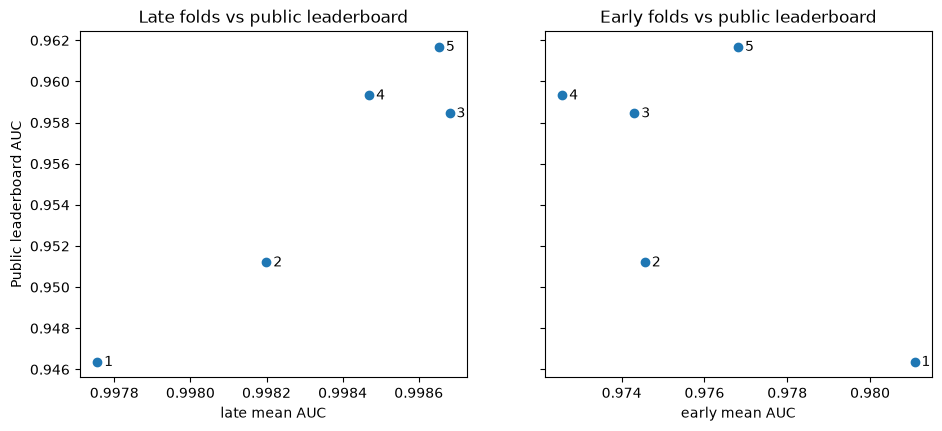

1 baseline
2 + graph features
3 two-stage, class weight, no offset
4 two-stage, class weight + offset
5 two-stage, no weight + offset


In [7]:
# One panel per fold set: each dot is a submitted model, labeled 1-5 in the order of the table above
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, col in zip(axes, ["late mean", "early mean"]):
    ax.scatter(submitted[col], submitted["public leaderboard"])
    for number, (x, y) in enumerate(zip(submitted[col], submitted["public leaderboard"]), start=1):
        ax.annotate(str(number), (x, y), xytext=(5, -3), textcoords="offset points")
    ax.set_xlabel(f"{col} AUC")
    ax.set_title(f"{col.split()[0].capitalize()} folds vs public leaderboard")
axes[0].set_ylabel("Public leaderboard AUC")
plt.show()

for number, name in enumerate(submitted.index, start=1):
    print(number, name)

**Takeaway:** the **late folds** order the five submitted models much like the leaderboard (rank correlation +0.70; with five models this is a rough guide, not proof).
- They got the two big steps right: the graph features and the neighbours' risk each raised both the late-fold AUC and the leaderboard.
- They missed the last step: they put the two offset models (dots 4 and 5) below the class-weight model without offset (dot 3), while the leaderboard put both above it.

The **early folds** disagree with the leaderboard (−0.40): they rank the baseline first, because the graph features lose on the first early fold (0.92807 vs 0.94845), the fold decided by step 24 (`02_validation_setup.ipynb`).
Choosing by the early folds would have rejected the graph features, my first clear leaderboard gain. The late folds were the better choice, but they cannot see the last step.

## 5. Every submission
All public scores are typed in from the Kaggle leaderboard.
Files marked "research" were made by one-off experiment scripts outside these notebooks; the others are rebuilt by the notebook named.

| # | Submission | What it tested | Public AUC | Rebuilt in |
|---|---|---|---|---|
| 1 | LightGBM (balanced) | Baseline, 165 raw features | 0.94637 | 03 |
| 2 | Self-training | LightGBM retrained with its most confident test predictions as extra labels | 0.94616 | research |
| 3 | Random forest (balanced) | Second baseline | 0.93650 | 03 |
| 4 | Regularised bag | Average of 5 LightGBMs with smaller trees | 0.94491 | research |
| 5 | Chain pooling | Raise the score of every transaction in a payment chain that holds a high-risk one | 0.93459 | research |
| 6 | Smooth models | Spline logistic regression blended with a small neural network | 0.93294 | research |
| 7 | Density ensemble | "How many similar transactions share this time step" features | 0.94370 | research |
| 8 | LightGBM, 1000 trees | Tuning: 1000 trees, 30% of the features per tree | 0.94261 | research |
| 9 | **+ graph features** | 27 present-neighbour graph features | **0.95121** | 04 |
| 10 | + graph, 1000 trees | Both changes together | 0.94802 | research |
| 11 | **+ neighbours' risk** | Two-stage model (stacking) | **0.95846** | 04 |
| 12 | + neighbours' risk, 2 hops | Risk of neighbours' neighbours as well | 0.95782 | research |
| 13 | Blend of 3 | Rank average of three neighbour-risk models | 0.95847 | research |
| 14 | Raise steps 43–49 | Shift the scores of the later test steps up | 0.95733 | research |
| 15 | **No weight + per-step offset** | The final model | **0.96169** | 05 |
| 16 | Drop 20 drifting columns | Remove the features that shift most into the test period | 0.95549 | research |
| 17 | Class weight + per-step offset | The offset alone | 0.95933 | 05 (model in section 3) |
| 18 | No weight + constant offset | No weight, one offset for all steps | 0.95888 | research |
| 19 | Final model without time proxies | Drop 6 columns that track the time step | 0.95758 | research |
| 20 | + fraud PageRank | Graph feature from the lectures: PageRank started from illicit transactions | 0.95715 | research |
| 21 | + communities | Graph feature from the lectures: community detection | 0.96136 | research |

**Takeaway:** Three submissions raised my best score (bold): the graph features (+0.00484 over the baseline), the neighbours' risk (+0.00725) and the final model (+0.00323). The other 17 scored below the best file of their time, or level with it (#13). What I learned:
- Tuning and other model types never helped (#3, #4, #6, #8, #10).
- #4 to #7 were chosen with folds that validate on step 24 without training on it, like the first early fold, and all scored below the baseline. This is why I moved to the late folds.
- Extending the neighbours' risk (#12, #13) or shifting scores by hand (#14) did not help.
- The two graph features from the lectures (#20, #21) did not beat the final model.

## 6. The final model and its submission
The final model is the two-stage model with **no class weight and a per-step offset** in both stages, trained on all labeled rows (steps 1–35).

**Steps:**
1. Train the two-stage model once per seed (42 to 47); both stages use the seed.
2. Average the six predicted probabilities and save `05_final_model.csv`.
3. Measure how far each single seed's ranking is from the average (Spearman rank correlation), to show what seed averaging removes.

The cell trains 42 LightGBM models (7 per seed), so it takes a few minutes.

In [8]:
FINAL_SEEDS = [42, 43, 44, 45, 46, 47]
final_model = two_stage(balanced=False, use_offset=True)

seed_probs = [final_model(lab_g, test_g, seed) for seed in FINAL_SEEDS]  # one prediction per seed
final_probs = np.mean(seed_probs, axis=0)                                # same as average_over_seeds(final_model, lab_g, test_g, FINAL_SEEDS)
print("Saved:", save_submission(test, final_probs, "05_final_model.csv").name)

# How much do single seeds disagree? Rank correlation of each seed's test predictions with the average
for seed, probs in zip(FINAL_SEEDS, seed_probs):
    print(f"seed {seed}: rank correlation with the 6-seed average {pd.Series(probs).corr(pd.Series(final_probs), method='spearman'):.4f}")

Saved: 05_final_model.csv
seed 42: rank correlation with the 6-seed average 0.9928
seed 43: rank correlation with the 6-seed average 0.9929
seed 44: rank correlation with the 6-seed average 0.9921
seed 45: rank correlation with the 6-seed average 0.9929
seed 46: rank correlation with the 6-seed average 0.9913
seed 47: rank correlation with the 6-seed average 0.9928


`05_final_model.csv` is the file behind my best public score: it was submitted as `probe_nocw_stepoff.csv` (0.96169).

**Takeaway:** Each single seed ranks the test rows almost, but not exactly, like the average (rank correlation 0.9913 to 0.9929). Averaging six seeds removes part of this seed-to-seed noise.

## 7. Ensembles
The final model is already an ensemble, in two ways:
- **Stacking:** for each seed, six stage-1 LightGBMs (five out-of-fold, one trained on all rows) produce the neighbours' risk features that the stage-2 LightGBM learns from.
- **Seed averaging:** the submission averages six two-stage models that differ only in their random seed, which changes the rows and features each tree is built from (section 6).

I also tried blending different model types in research runs, before the last step: CatBoost, XGBoost, ExtraTrees and scikit-learn's HistGradientBoosting, each blended with the two-stage model.
None beat the two-stage model on the late folds, so none was submitted. The one blend I submitted (#13, three neighbour-risk models) scored 0.95847, level with the single model's 0.95846.

## 8. The two final submissions
Kaggle ranks each team on the private leaderboard (the other 70% of test rows) with the better of its two selected files.
So the second file should be good on its own but **different** from the first: it only helps if the first one fails.

The cell measures how different the two picks are: the rank correlation of their test predictions, and the overlap of the 1,000 transactions each ranks as most suspicious.

In [9]:
pick_1 = pd.read_csv(SUBMISSIONS_DIR / "05_final_model.csv")["target"]
pick_2 = pd.read_csv(SUBMISSIONS_DIR / "04_neighbour_risk.csv")["target"]  # written by 04_graph_features.ipynb
print(f"Rank correlation between the two picks' test predictions: {pick_1.corr(pick_2, method='spearman'):.4f}")

# Of the 1,000 test transactions each pick ranks as most suspicious, how many are the same?
top_1, top_2 = set(pick_1.nlargest(1000).index), set(pick_2.nlargest(1000).index)
print(f"Shared among the top 1,000: {len(top_1 & top_2)}")

Rank correlation between the two picks' test predictions: 0.9845
Shared among the top 1,000: 940


| Pick | File | Public AUC | Why |
|---|---|---|---|
| 1 | `05_final_model.csv` (submitted as `probe_nocw_stepoff.csv`) | **0.96169** | Best public score |
| 2 | `04_neighbour_risk.csv` (submitted as `probe_neighbour_risk.csv`) | 0.95846 | Best model **without** the last step. The last step was chosen on the public leaderboard alone (section 3); if its gain is noise in the public 30%, this file does not share it |

**Takeaway:** the two picks rank the test rows similarly (rank correlation 0.9845) but not identically: 940 of their 1,000 most suspicious test transactions are the same. Pick 2 is the strongest file that does not depend on the per-step offset.

The communities probe (#21, 0.96136) has the second-best public score, but it is the final model plus one feature, so it would fail in the same way as pick 1. I did not pick it.

## 9. Limitations
- **Validation could not rank the last step.** That choice rests on the public leaderboard, which uses only 30% of the test rows.
- **Validation is far above the leaderboard** (about 0.998, against 0.946 to 0.962 for the submitted models in section 3), so the folds only tell which model is better, not how well it will score.
- **Illicit patterns that first appear after step 35 cannot be learned.** Step 24 showed such a pattern inside the training period (`02_validation_setup.ipynb`).
- **About a quarter of test rows (25.4%) have no present neighbour** (`04_graph_features.ipynb`); for them the neighbour features are missing.
- **The present rule assumes test.csv holds the labeled test-period transactions**, which I inferred from the data (`01_eda.ipynb`).

## 10. Summary
| Question | Answer |
|---|---|
| No class weight + per-step offset? | Public leaderboard 0.95846 → **0.96169** (+0.00323); each change alone gained much less. The late folds tie (0.99865 vs 0.99868) |
| Did the late folds match the leaderboard? | Mostly: rank correlation +0.70 (early folds −0.40). They picked the graph features and the neighbours' risk, but could not see the last step |
| Final model | Two-stage LightGBM, no class weight, per-step offset in both stages, 6 seeds: `submissions/05_final_model.csv`, public 0.96169 |
| Ensemble | Stacking (two stages) and seed averaging; blends with other model types did not help |
| Final picks | `05_final_model.csv` (0.96169) and `04_neighbour_risk.csv` (0.95846) |